# Bloque 3: Comparaciones y tests

En este bloque contrastamos hipótesis sobre los conteos. Como conocemos cómo se generan los datos, además de aplicar cada test una vez vamos a estimar por simulación con qué frecuencia rechaza: si $H_0$ es verdadera, esa proporción estima el **nivel** del test; si es falsa, estima su **potencia**.

Todos los tests pueden calcularse con `scipy.stats`; no es necesario programar los estadísticos a mano. Como la proporción de rechazos se estima varias veces, conviene escribir una única función, por ejemplo `proporcion_rechazos(generar_par, test, R)`, que llame $R$ veces a `generar_par()` (que devuelve un par de muestras nuevas), aplique `test` a cada par y devuelva la proporción de $p$-valores menores que 0,05.

---

## Setup

In [10]:
# Imports
import json
import numpy as np
import pandas as pd
from codigo_base import *
import scipy.stats as stats
import matplotlib.pyplot as plt

# Estilo de los gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlesize": 11,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

# Variables globales
rng = np.random.default_rng(4)

# Datos: una medición por renglón
df = pd.read_json("conteos.jsonl", lines=True)
df.head()

,experimento,algoritmo,n,k,lista,swaps,comparaciones
0,uniforme,insertion,100,NaN,0,2304,2398
1,uniforme,selection,100,NaN,0,94,4950
2,uniforme,quick_primero,100,NaN,0,373,604
3,uniforme,quick_medio,100,NaN,0,351,635
4,uniforme,insertion,100,NaN,1,2447,2543


### Datos del experimento `uniforme`

Arrays `S` (swaps de insertion sort) y `Q` (comparaciones de quicksort con pivote en el primer elemento), ordenados por `lista`.

In [11]:
uniforme = df[df["experimento"] == "uniforme"]

S = (uniforme[uniforme["algoritmo"] == "insertion"]
     .sort_values("lista")["swaps"].to_numpy())
Q = (uniforme[uniforme["algoritmo"] == "quick_primero"]
     .sort_values("lista")["comparaciones"].to_numpy())

print(f"len(S) = {len(S)}, media = {S.mean():.2f}  (teórica: {100*99/4:.2f})")
print(f"len(Q) = {len(Q)}, media = {Q.mean():.2f}  (teórica: 647.85)")

len(S) = 2000, media = 2470.13  (teórica: 2475.00)
len(Q) = 2000, media = 645.28  (teórica: 647.85)


---

## Herramientas

- **Test de Shapiro–Wilk** (`scipy.stats.shapiro`). $H_0$: los datos son una muestra de alguna distribución normal, con media y varianza no especificadas. No lo vimos en clase: forma parte del trabajo investigarlo.
- **Test $t$ de Welch** (`scipy.stats.ttest_ind` con `equal_var=False`). $H_0$: $\mu_X = \mu_Y$, sin suponer que las dos varianzas son iguales. Usa el estadístico
$$T = \frac{\bar X - \bar Y}{\sqrt{s_X^2/N_X + s_Y^2/N_Y}},$$
que bajo $H_0$ tiene distribución aproximadamente $t$, con grados de libertad estimados a partir de los datos.
- **Test de permutaciones** (para el ítem optativo 3.2 d). $H_0$: las dos muestras provienen de la misma distribución. Si $H_0$ es cierta, la etiqueta de cada observación (a qué muestra pertenece) no importa. Se juntan las $N_X + N_Y$ observaciones, se las reparte al azar en dos grupos de tamaños $N_X$ y $N_Y$, se recalcula la diferencia de medias, y se repite esto $B$ veces. El $p$-valor es la proporción de repartos en los que la diferencia, en valor absoluto, es al menos tan grande como la observada. Puede programarse a mano o con `scipy.stats.permutation_test`.
- **Intervalo bootstrap percentil** (para el ítem 3.5). Para un estadístico $\hat\theta$ calculado a partir de una muestra: se generan $B$ muestras bootstrap, cada una tomando $N$ valores con reposición de la muestra original; se calcula $\hat\theta$ en cada una, y el intervalo de nivel 0,95 va del percentil 2,5 al percentil 97,5 de esos $B$ valores (`scipy.stats.bootstrap` con `method="percentile"`).

---

## Función auxiliar: `proporcion_rechazos`

`proporcion_rechazos(generar_par, test, R)`: llama $R$ veces a `generar_par()`, aplica `test` a cada par y devuelve la proporción de $p$-valores menores que 0,05.

---

## Ejercicio 3.1: Normalidad

### 3.1 a)

Investigue el test de Shapiro–Wilk: qué compara su estadístico y qué valores llevan a rechazar $H_0$. ¿Qué relación tiene con el gráfico cuantil-cuantil contra la normal?

--- 

El test de Shapiro–Wilk es para evaluar si una muestra proviene de una población con distribución normal.

$$
W = \frac{\left(\displaystyle\sum_{i=1}^{N} a_i\, x_{(i)}\right)^2}{\displaystyle\sum_{i=1}^{N} (x_i - \bar{x})^2}
$$



Su estadístico $W$ compara dos estimaciones de la varianza de la muestra, una basada en datos ordenados y en los valores esperados de una distribución normal (el numerador) y la otra es la varianza muestral habitual (el denominador). Si los datos son normales, ambas estimaciones son similares. 
Esto significa que el estadístico $W$ del test toma valores entre 0 y 1. Valores cercanos a 0 indican que los datos no pertenecen a una distribución normal. Por eso se rechaza $H_0$ cuando $W$ es chico, que es lo mismo que un p-valor chico ($p < 0,05$).


#### Cómo se arma un QQ-plot contra la normal:
1. Ordenás tus datos de menor a mayor: $x_{(1)} \le x_{(2)} \le \dots \le x_{(N)}$. El dato $x_{(i)}$ es el cuantil empírico de orden aproximadamente $i/N$ de tu muestra.
2. Para cada $i$ calculás el cuantil de una $N(0,1)$ con esa misma proporción, aproximadamente $m_i = \Phi^{-1}\left(\frac{i-0.5}{N}\right)$. Es el valor que "debería" ocupar el puesto $i$ si los datos fueran normales estándar.
3. Graficás los puntos $(m_i,\ x_{(i)})$: en el eje x los cuantiles teóricos y en el eje y tus datos ordenados.

Entonces cada eje responde una pregunta distinta sobre el mismo puesto $i$:
- Eje X ($m_i$): dónde estaría el $i$-ésimo más chico si los datos fueran $N(0,1)$. Depende solo de $i$ y $N$; no de los datos.
- Eje Y ($x_{(i)}$): dónde está de verdad el $i$-ésimo más chico en los datos.

#### Relación QQ-plot y Test Shapiro-Wilk

Si los datos son normales, los puntos $(m_i,\ x_{(i)})$ del QQ-plot quedan sobre una recta de ordenada $\mu$ y pendiente $\sigma$, porque una $N(\mu, \sigma^2)$ es una $N(0,1)$ corrida en $\mu$ y estirada por $\sigma$. Si los datos no son normales, los puntos se curvan.

El estadístico $W$ mide qué tan recto es el QQ-plot. Es aproximadamente el cuadrado de la correlación entre los cuantiles teóricos $m_i$ y los datos ordenados $x_{(i)}$: vale 1 si los puntos están perfectamente alineados y baja a medida que se curvan. Por ejemplo, con 200 datos simulados de una normal el $r^2$ del QQ-plot da $0{,}992$ y $W = 0{,}989$, y con 200 datos de una exponencial $r^2 = 0{,}776$ y $W = 0{,}782$.

Con datos normales los puntos igual oscilan un poco alrededor de la recta por azar, así que $W$ queda un poco por debajo de 1. El p-valor mide qué tan probable es obtener un $W$ así de chico si los datos fueran normales. Si es menor a $0{,}05$ se rechaza $H_0$.

Los dos se complementan: el QQ-plot muestra cómo se apartan los datos de la normal (asimetría, colas pesadas), y el test dice si ese apartamiento es más grande de lo que explicaría el azar.

---

### 3.1 b)

Aplíquelo a $S_{100}$ y a $Q_{100}$ usando las primeras $N = 50, 200, 1000$ y $2000$ listas del experimento `uniforme`, junto con gráficos cuantil-cuantil. ¿Cómo cambian los $p$-valores con $N$ en cada caso?

---

In [19]:
Ns = [50, 200, 1000, 2000]
variables = {"S_100": S, "Q_100": Q}

# Shapiro–Wilk sobre las primeras N listas de cada variable
resultados = {}
for nombre, datos in variables.items():
    for N in Ns:
        W, p = stats.shapiro(datos[:N])
        resultados[(nombre, N)] = (W, p)

tabla = pd.DataFrame(
    {(nombre, col): [resultados[(nombre, N)][j] for N in Ns]
     for nombre in variables for j, col in enumerate(["W", "p-valor"])},
    index=pd.Index(Ns, name="N"),
)
# W con 4 decimales; p-valor en notación científica (los de Q son muy chicos)
tabla.apply(lambda col: col.map("{:.4f}".format if col.name[1] == "W" else "{:.2e}".format))

S_100             Q_100          
           W   p-valor       W   p-valor
N                                       
50    0.9840  7.30e-01  0.9401  1.36e-02
200   0.9928  4.37e-01  0.9662  9.77e-05
1000  0.9985  5.56e-01  0.9550  5.95e-17
2000  0.9993  6.68e-01  0.9607  7.35e-23

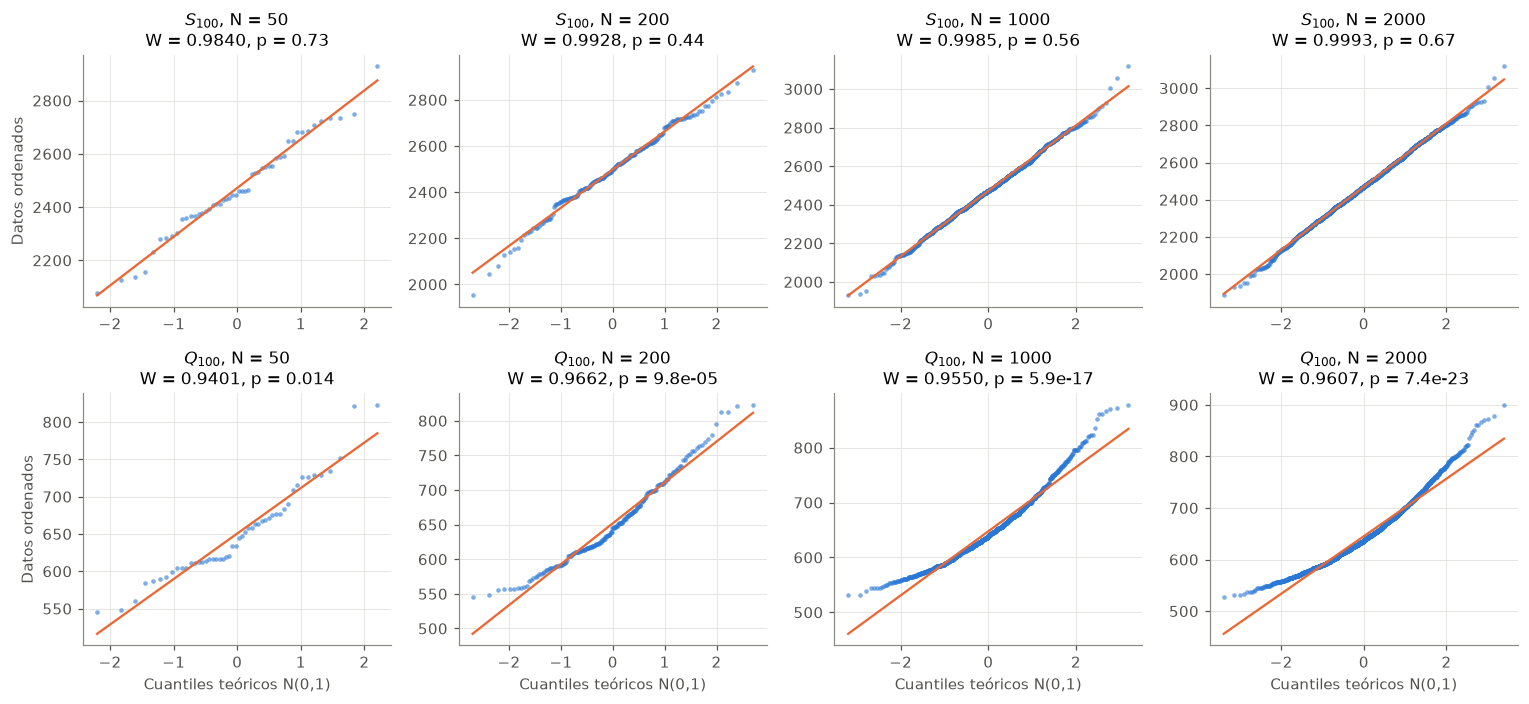

In [13]:
fig, axes = plt.subplots(2, len(Ns), figsize=(14, 6.5))

for fila, (nombre, datos) in enumerate(variables.items()):
    etiqueta = nombre.replace("_100", "_{100}")
    for col, N in enumerate(Ns):
        ax = axes[fila, col]
        stats.probplot(datos[:N], dist="norm", plot=ax)
        puntos, recta = ax.get_lines()
        puntos.set(color=AZUL, markersize=3, alpha=0.6, markeredgewidth=0)
        recta.set(color=NARANJA, linewidth=1.5)

        W, p = resultados[(nombre, N)]
        ax.set_title(f"${etiqueta}$, N = {N}\nW = {W:.4f}, p = {p:.2g}")
        ax.set_xlabel("Cuantiles teóricos N(0,1)" if fila == 1 else "")
        ax.set_ylabel("Datos ordenados" if col == 0 else "")

plt.tight_layout()
plt.show()

El QQ Plot es consistente con el del ejercicio 1.2. Muestra que $Q_{100}$ tiene una distribución asimétrica a derecha: en los dos extremos los puntos quedan por encima de la recta, o sea que la cola derecha es larga y la izquierda es corta. Coincide con el $\hat{\gamma}_Q \approx 0{,}83$ positivo del 1.2.

El p-valor en $Q_{100}$ es muy chico para todos los $N$, lo cual significa que se rechaza $H_0$. Tiene sentido porque $Q$ es asimétrica. Además el p-valor baja mucho a medida que crece $N$ (de $0{,}014$ con $N = 50$ a $7 \cdot 10^{-23}$ con $N = 2000$), mientras que $W$ se mantiene parecido (entre $0{,}94$ y $0{,}97$).

Por otro lado $S_{100}$ tiene p-valores grandes para todos los $N$ y sin ninguna tendencia: suben y bajan al azar. El test nunca rechaza, lo cual significa que los datos son compatibles con una normal.

A medida que aumentamos $N$ el test se vuelve más sensible, porque con más datos el QQ-plot de una normal oscila menos y $W$ queda más cerca de 1. Por eso el mismo desvío de $Q$ se detecta cada vez con más claridad, mientras que en $S$ no aparece ningún desvío y el p-valor se mueve al azar.

---

### 3.1 c)

Un único $p$-valor con $N$ chico cambia mucho de una muestra a otra. Para $N = 50$, divida las 2000 listas en 40 bloques disjuntos y calcule, para $S_{100}$ y para $Q_{100}$, en qué proporción de ellos el test rechaza al nivel 0,05. ¿Qué estima cada proporción? $S_{100}$ no es exactamente normal: toma valores enteros entre 0 y 4950. ¿Por qué el test casi nunca lo detecta? ¿Se puede concluir de un no rechazo que los datos son normales? (Ayuda: recuerde la definición de potencia.)

---

In [ ]:
N_bloque, n_bloques = 50, 40

# p-valores de Shapiro–Wilk en cada bloque disjunto de 50 listas
pvalores = {
    nombre: np.array([stats.shapiro(bloque)[1] for bloque in datos.reshape(n_bloques, N_bloque)])
    for nombre, datos in variables.items()
}

for nombre, p in pvalores.items():
    print(f"{nombre}: rechaza en {np.sum(p < 0.05):2d} de {n_bloques} bloques  ->  proporción = {np.mean(p < 0.05):.3f}")

Distribución de los 40 p-valores de cada variable. La línea punteada marca el nivel 0,05: los bloques a su izquierda son los que rechazan.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
bordes = np.linspace(0, 1, 21)

for ax, (nombre, p), color in zip(axes, pvalores.items(), [AZUL, NARANJA]):
    etiqueta = nombre.replace("_100", "_{100}")
    ax.hist(p, bins=bordes, color=color, edgecolor="white")
    ax.axvline(0.05, color=GRIS, linestyle="--", linewidth=1, label="0,05")
    ax.set_title(f"${etiqueta}$: p-valores en {n_bloques} bloques de N = {N_bloque}")
    ax.set_xlabel("p-valor")
    ax.legend()
axes[0].set_ylabel("Cantidad de bloques")
plt.tight_layout()
plt.show()

Escala de $S_{100}$, para comparar el tamaño de los escalones (valores enteros) y de los límites $0$ y $4950$ con su desvío.

In [ ]:
# Escala de S_100: desvío teórico y a cuántos desvíos están los extremos posibles
n = 100
mu_S = n * (n - 1) / 4
sigma_S = np.sqrt(n * (n - 1) * (2 * n + 5) / 72)
print(f"mu_S = {mu_S:.0f},  sigma_S = {sigma_S:.1f}")
print(f"Un escalón de 1 equivale a {1 / sigma_S:.4f} desvíos")
print(f"El 0 está a {(0 - mu_S) / sigma_S:.1f} desvíos de la media y el 4950 a {(4950 - mu_S) / sigma_S:.1f}")
print(f"P(|Z| > {mu_S / sigma_S:.1f}) para una normal = {2 * stats.norm.sf(mu_S / sigma_S):.1e}")

Cada bloque es una muestra independiente de 50 listas, así que la proporción de bloques en los que el test rechaza estima la probabilidad de que el test rechace con $N = 50$. Si $H_0$ es verdadera esa probabilidad es el nivel del test, y si $H_0$ es falsa es su potencia.

Para $Q_{100}$ el test rechaza en 24 de los 40 bloques (proporción $0{,}60$). Como $Q$ es asimétrica, $H_0$ es falsa, lo cual significa que $0{,}60$ estima la potencia del test con $N = 50$ para detectar que $Q_{100}$ no es normal. En 4 de cada 10 muestras el test no lo detecta (error de tipo II). Tiene sentido con el ítem b): con $N$ chico el test tiene menos potencia, y con $N$ grande rechazaba siempre.

Por otro lado $S_{100}$ rechaza en 4 de los 40 bloques (proporción $0{,}10$). Si $S_{100}$ fuera normal, esa proporción estimaría el nivel, que vale $0{,}05$. La diferencia entre $0{,}10$ y $0{,}05$ se explica por el azar de tener solo 40 bloques: si la probabilidad de rechazo fuera $0{,}05$, la cantidad de rechazos sería $\text{Binomial}(40;\ 0{,}05)$, con 2 rechazos esperados, y obtener 4 o más pasa con probabilidad $\approx 0{,}14$. Además el histograma muestra los p-valores repartidos de forma pareja entre 0 y 1, como pasa cuando $H_0$ es verdadera.

$S_{100}$ toma valores enteros entre 0 y 4950, así que estrictamente $H_0$ es falsa y la proporción también estima una potencia. El test casi nunca lo detecta porque la diferencia con una normal es muy chica comparada con su desvío $\sigma_S \approx 167{,}9$: un escalón de 1 equivale a $0{,}006$ desvíos, y los límites 0 y 4950 están a $14{,}7$ desvíos de la media, donde una normal tiene probabilidad $\approx 10^{-49}$. Con 50 datos el test ve a $S_{100}$ igual que a una normal, y su potencia queda prácticamente igual al nivel.

Por eso de un no rechazo no se puede concluir que los datos sean normales. La potencia del test contra esta diferencia es casi $0{,}05$, lo cual significa que el test no rechaza en el 95% de los casos aunque $H_0$ sea falsa. Un no rechazo solo dice que la diferencia con una normal, si existe, es demasiado chica para detectarla con esos datos.

---

## Ejercicio 3.2: Nivel y potencia: el efecto del desorden

Compare las comparaciones de quicksort $Q_{100}$ sobre permutaciones uniformes de 100 elementos con las obtenidas sobre listas de 100 elementos con desorden $k$, usando $N = 50$ listas nuevas de cada tipo y $R = 300$ repeticiones.

### 3.2 a)

**Nivel.** Compare dos muestras independientes de permutaciones uniformes con un test de Welch y estime la proporción de rechazos. ¿Qué cantidad está estimando y cuánto debería valer? (Ayuda: recuerde que el nivel es la probabilidad de rechazar $H_0$ cuando $H_0$ es verdadera, es decir, de cometer un error de tipo I; la potencia es la probabilidad de rechazar $H_0$ cuando $H_1$ es verdadera, es decir, $1 - P(\text{error de tipo II})$.)

---

_Respuesta:_

---

### 3.2 b)

**Potencia.** Para $k = 50, 75, 100, 125, 150, 200, 300$, estime la proporción de rechazos del test de Welch y grafíquela en función de $k$.

---

_Respuesta:_

---

### 3.2 c)

¿A partir de qué $k$ deja de detectarse una diferencia? Que el test no rechace, ¿significa que las dos distribuciones son iguales? Para $k = 200$, estime la proporción de rechazos con $N = 5000$ listas de cada tipo ($R = 100$ repeticiones alcanzan) y compárela con la que obtuvo con $N = 50$.

---

_Respuesta:_

---

### 3.2 d)

**(Optativo)** Repita a) y, para $k = 100$ y $k = 150$, b) con un test de permutaciones ($B = 1000$ permutaciones), usando $R = 1000$ repeticiones. Compare con el test de Welch. ¿Qué hipótesis nula contrasta cada uno? $Q_{100}$ es asimétrica: ¿por qué, con muestras del mismo tamaño, eso casi no afecta el nivel del test de Welch? (Ayuda: con el ítem 2.2, calcule la asimetría de $\bar X - \bar Y$ cuando $X$ e $Y$ tienen la misma distribución y $N_X = N_Y$.)

---

_Respuesta:_

---

## Ejercicio 3.3: Comparaciones apareadas

Como la función `medir` corre todos los algoritmos sobre las mismas listas, las mediciones de un mismo experimento pueden aparearse.

### 3.3 a)

Con el experimento `uniforme`, calcule la correlación entre $S_{100}$ y $Q_{100}$. Usando $\operatorname{Var}(X - Y) = \operatorname{Var}(X) + \operatorname{Var}(Y) - 2\operatorname{Cov}(X, Y)$, ¿aparear reduciría la variabilidad de la diferencia en este caso?

---

_Respuesta:_

---

### 3.3 b)

Repita con las comparaciones $C_{100}$ y los swaps $S_{100}$ de insertion sort. Con $N = 10$ listas, contraste $H_0: \mathrm{E}(C_{100}) = \mathrm{E}(S_{100})$ con un test $t$ no apareado y con uno apareado (`scipy.stats.ttest_rel`). Repita $R = 1000$ veces con listas nuevas y compare la proporción de rechazos de ambos tests.

---

_Respuesta:_

---

### 3.3 c)

**(Optativo)** Explique la diferencia. ¿Por qué $C_{100} - S_{100}$ varía tan poco de una lista a otra? (Ayuda: en cada iteración del **para** de insertion sort, ¿cuántas comparaciones no terminan en un swap?)

---

_Respuesta:_

---

## Ejercicio 3.4: ANOVA

Considere $g = 4$ grupos de listas con desorden $k = 100, 150, 200$ y $300$, con 100 listas nuevas por grupo.

### 3.4 a)

Plantee las hipótesis del ANOVA de un factor para comparar $\mathrm{E}(Q_{100} \mid k)$ entre los cuatro grupos, calcule el estadístico $F$ (`scipy.stats.f_oneway`) y concluya.

---

_Respuesta:_

---

### 3.4 b)

¿Se cumplen los supuestos del ANOVA? Compare los desvíos de los grupos y describa la forma de cada distribución.

---

_Respuesta:_

---

### 3.4 c)

Haga las 6 comparaciones de a pares con tests de Welch (que no suponen varianzas iguales) y corrección de Bonferroni. ¿Qué grupos difieren? ¿Es posible que el ANOVA rechace y ninguna comparación de a pares resulte significativa? ¿Por qué?

---

_Respuesta:_

---

## Ejercicio 3.5: Bootstrap

La mediana de $Q_{100}$ no tiene una fórmula sencilla. Sea $\delta$ la diferencia entre la mediana de las comparaciones de quicksort con desorden $k = 100$ y la mediana sobre permutaciones uniformes.

### 3.5 a)

Con $N = 50$ listas de cada tipo, construya un intervalo bootstrap percentil de nivel 0,95 para $\delta$, remuestreando cada grupo por separado ($B = 1000$).

---

_Respuesta:_

---

### 3.5 b)

Si el intervalo no contiene al 0, ¿qué se puede concluir? Repitiendo la construcción $R = 200$ veces con muestras nuevas, estime con qué frecuencia el intervalo excluye al 0. Haga lo mismo con un intervalo bootstrap para la diferencia de *medias*, y compare las dos frecuencias con la proporción de rechazos del test de Welch para $k = 100$ del ítem 3.2. ¿Por qué el intervalo basado en medianas excluye al 0 con menos frecuencia?

---

_Respuesta:_